In [5]:
# Tiny Shakespeare — Dataset Exploration

## Project: Building an LLM from Scratch

#In this notebook, we explore the raw Tiny Shakespeare dataset before performing any cleaning or preprocessing.

### Objectives

# - Load the raw dataset
# - Inspect the dataset structure
# - Determine the dataset size
# - Examine sample text
# - Analyze characters
# - Calculate vocabulary size
#- Identify unusual characters
# - Analyze character frequencies
# - Understand the data before preprocessing

# **Important:** The raw dataset will not be modified in this notebook.

In [6]:
import os
import re
from collections import Counter

import matplotlib.pyplot as plt

In [7]:
DATA_PATH = "../data/raw/tiny-shakespeare.txt"

print("Dataset path:", DATA_PATH)
print("File exists:", os.path.exists(DATA_PATH))

Dataset path: ../data/raw/tiny-shakespeare.txt
File exists: True


In [8]:
with open(DATA_PATH, "r", encoding="utf-8") as file:
    text = file.read()

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [9]:
print(text[:1000])

First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us kill him, and we'll have corn at our own price.
Is't a verdict?

All:
No more talking on't; let it be done: away, away!

Second Citizen:
One word, good citizens.

First Citizen:
We are accounted poor citizens, the patricians good.
What authority surfeits on would relieve us: if they
would yield us but the superfluity, while it were
wholesome, we might guess they relieved us humanely;
but they think we are too dear: the leanness that
afflicts us, the object of our misery, is as an
inventory to particularise their abundance; our
sufferance is a gain to them Let us revenge this with
our pikes, ere we become rakes: for the gods know I
speak this in hunger for bread, not in thirst for revenge.



In [10]:
num_characters = len(text)

print("Total characters:", num_characters)

Total characters: 1115394


In [11]:
size_mb = os.path.getsize(DATA_PATH) / (1024 * 1024)

print(f"File size: {size_mb:.2f} MB")

File size: 1.06 MB


In [12]:
num_lines = text.count("\n") + 1
num_words = len(text.split())

print("Characters:", num_characters)
print("Lines:", num_lines)
print("Words:", num_words)

Characters: 1115394
Lines: 40001
Words: 202651


In [13]:
unique_characters = sorted(set(text))

print("Number of unique characters:", len(unique_characters))
print("\nCharacters:")
print(unique_characters)

Number of unique characters: 65

Characters:
['\n', ' ', '!', '$', '&', "'", ',', '-', '.', '3', ':', ';', '?', 'A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z', 'a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k', 'l', 'm', 'n', 'o', 'p', 'q', 'r', 's', 't', 'u', 'v', 'w', 'x', 'y', 'z']


In [14]:
char_counts = Counter(text)

for char, count in char_counts.most_common(20):
    display_char = repr(char)
    print(f"{display_char:>6} : {count}")


   ' ' : 169892
   'e' : 94611
   't' : 67009
   'o' : 65798
   'a' : 55507
   'h' : 51310
   's' : 49696
   'r' : 48889
   'n' : 48529
   'i' : 45537
  '\n' : 40000
   'l' : 33339
   'd' : 31358
   'u' : 26584
   'm' : 22243
   'y' : 20448
   ',' : 19846
   'w' : 17585
   'f' : 15770
   'c' : 15623


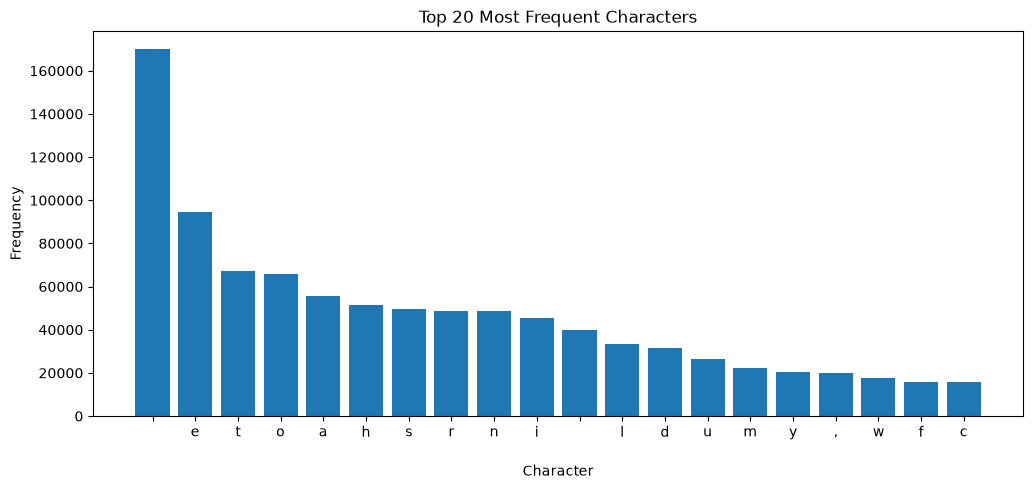

In [15]:
characters, frequencies = zip(*char_counts.most_common(20))

plt.figure(figsize=(12, 5))
plt.bar(characters, frequencies)

plt.title("Top 20 Most Frequent Characters")
plt.xlabel("Character")
plt.ylabel("Frequency")

plt.show()

In [16]:
print("All unique characters:\n")

for i, char in enumerate(unique_characters):
    print(i, repr(char))

All unique characters:

0 '\n'
1 ' '
2 '!'
3 '$'
4 '&'
5 "'"
6 ','
7 '-'
8 '.'
9 '3'
10 ':'
11 ';'
12 '?'
13 'A'
14 'B'
15 'C'
16 'D'
17 'E'
18 'F'
19 'G'
20 'H'
21 'I'
22 'J'
23 'K'
24 'L'
25 'M'
26 'N'
27 'O'
28 'P'
29 'Q'
30 'R'
31 'S'
32 'T'
33 'U'
34 'V'
35 'W'
36 'X'
37 'Y'
38 'Z'
39 'a'
40 'b'
41 'c'
42 'd'
43 'e'
44 'f'
45 'g'
46 'h'
47 'i'
48 'j'
49 'k'
50 'l'
51 'm'
52 'n'
53 'o'
54 'p'
55 'q'
56 'r'
57 's'
58 't'
59 'u'
60 'v'
61 'w'
62 'x'
63 'y'
64 'z'


In [17]:
total_chars = len(text)

char_frequency = {
    char: count / total_chars
    for char, count in char_counts.items()
}

for char, frequency in sorted(
    char_frequency.items(),
    key=lambda x: x[1],
    reverse=True
)[:20]:

    print(f"{repr(char):>6} : {frequency * 100:.2f}%")

   ' ' : 15.23%
   'e' : 8.48%
   't' : 6.01%
   'o' : 5.90%
   'a' : 4.98%
   'h' : 4.60%
   's' : 4.46%
   'r' : 4.38%
   'n' : 4.35%
   'i' : 4.08%
  '\n' : 3.59%
   'l' : 2.99%
   'd' : 2.81%
   'u' : 2.38%
   'm' : 1.99%
   'y' : 1.83%
   ',' : 1.78%
   'w' : 1.58%
   'f' : 1.41%
   'c' : 1.40%


In [18]:
lines = text.splitlines()

longest_line = max(lines, key=len)

print("Longest line length:", len(longest_line))
print("\nLongest line:")
print(longest_line)

Longest line length: 63

Longest line:
should buy the fee-simple of my life for an hour and a quarter.


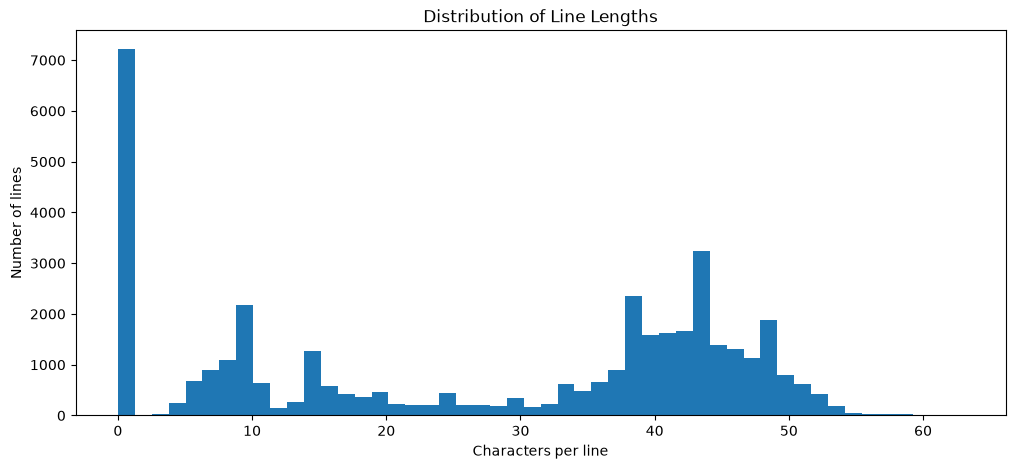

In [19]:
line_lengths = [len(line) for line in lines]

plt.figure(figsize=(12, 5))

plt.hist(line_lengths, bins=50)

plt.title("Distribution of Line Lengths")
plt.xlabel("Characters per line")
plt.ylabel("Number of lines")

plt.show()

In [20]:
print("=" * 50)
print("DATASET SUMMARY")
print("=" * 50)

print(f"File size           : {size_mb:.2f} MB")
print(f"Characters          : {num_characters:,}")
print(f"Words               : {num_words:,}")
print(f"Lines               : {num_lines:,}")
print(f"Unique characters   : {len(unique_characters)}")
print(f"Longest line        : {len(longest_line)} characters")

print("=" * 50)

DATASET SUMMARY
File size           : 1.06 MB
Characters          : 1,115,394
Words               : 202,651
Lines               : 40,001
Unique characters   : 65
Longest line        : 63 characters


In [22]:
print("UNIQUE CHARACTERS")
print("=" * 50)

for i, char in enumerate(unique_characters):
    print(f"{i:2d} : {repr(char)}")

UNIQUE CHARACTERS
 0 : '\n'
 1 : ' '
 2 : '!'
 3 : '$'
 4 : '&'
 5 : "'"
 6 : ','
 7 : '-'
 8 : '.'
 9 : '3'
10 : ':'
11 : ';'
12 : '?'
13 : 'A'
14 : 'B'
15 : 'C'
16 : 'D'
17 : 'E'
18 : 'F'
19 : 'G'
20 : 'H'
21 : 'I'
22 : 'J'
23 : 'K'
24 : 'L'
25 : 'M'
26 : 'N'
27 : 'O'
28 : 'P'
29 : 'Q'
30 : 'R'
31 : 'S'
32 : 'T'
33 : 'U'
34 : 'V'
35 : 'W'
36 : 'X'
37 : 'Y'
38 : 'Z'
39 : 'a'
40 : 'b'
41 : 'c'
42 : 'd'
43 : 'e'
44 : 'f'
45 : 'g'
46 : 'h'
47 : 'i'
48 : 'j'
49 : 'k'
50 : 'l'
51 : 'm'
52 : 'n'
53 : 'o'
54 : 'p'
55 : 'q'
56 : 'r'
57 : 's'
58 : 't'
59 : 'u'
60 : 'v'
61 : 'w'
62 : 'x'
63 : 'y'
64 : 'z'


In [23]:
print("SPECIAL / WHITESPACE CHARACTERS")
print("=" * 50)

for char in unique_characters:
    if char.isspace():
        print(repr(char), "→ whitespace")

SPECIAL / WHITESPACE CHARACTERS
'\n' → whitespace
' ' → whitespace


In [24]:
print("TOP 20 CHARACTERS")
print("=" * 50)

for char, count in char_counts.most_common(20):
    percentage = (count / num_characters) * 100
    print(f"{repr(char):>6} : {count:>8,} ({percentage:>6.2f}%)")

TOP 20 CHARACTERS
   ' ' :  169,892 ( 15.23%)
   'e' :   94,611 (  8.48%)
   't' :   67,009 (  6.01%)
   'o' :   65,798 (  5.90%)
   'a' :   55,507 (  4.98%)
   'h' :   51,310 (  4.60%)
   's' :   49,696 (  4.46%)
   'r' :   48,889 (  4.38%)
   'n' :   48,529 (  4.35%)
   'i' :   45,537 (  4.08%)
  '\n' :   40,000 (  3.59%)
   'l' :   33,339 (  2.99%)
   'd' :   31,358 (  2.81%)
   'u' :   26,584 (  2.38%)
   'm' :   22,243 (  1.99%)
   'y' :   20,448 (  1.83%)
   ',' :   19,846 (  1.78%)
   'w' :   17,585 (  1.58%)
   'f' :   15,770 (  1.41%)
   'c' :   15,623 (  1.40%)


In [25]:
unusual_chars = ['$', '&', '3']

for char in unusual_chars:
    print("=" * 60)
    print(f"Occurrences of {repr(char)}")
    print("=" * 60)

    positions = [i for i, c in enumerate(text) if c == char]

    print("Number of occurrences:", len(positions))

    for position in positions[:10]:
        start = max(0, position - 50)
        end = min(len(text), position + 50)

        print("\nContext:")
        print(repr(text[start:end]))

Occurrences of '$'
Number of occurrences: 1

Context:
'l brooks to flow:\nNow stops thy spring; my sea sha$l suck them dry,\nAnd swell so much the higher by '
Occurrences of '&'
Number of occurrences: 3

Context:
" answer.\n\nCORIOLANUS:\nHence, old goat!\n\nSenators, &C:\nWe'll surety him.\n\nCOMINIUS:\nAged sir, hands o"

Context:
"itizens:\nDown with him! down with him!\n\nSenators, &C:\nWeapons, weapons, weapons!\n'Tribunes!' 'Patric"

Context:
" king of\nEngland and France, and lord of Ireland, &c.\n\nMONTAGUE:\nAnd whosoe'er gainsays King Edward'"
Occurrences of '3'
Number of occurrences: 27

Context:
'\nEXETER:\nAnd I, I hope, shall reconcile them all.\n3 KING HENRY VI\n\nRICHARD:\nBrother, though I be you'

Context:
' one:\nWhy should I not now have the like success?\n3 KING HENRY VI\n\nRUTLAND:\nAh, whither shall I fly '

Context:
"d,\nCongeal'd with this, do make me wipe off both.\n3 KING HENRY VI\n\nYORK:\nThe army of the queen hath "

Context:
'ork gates;\nSo York may overl

In [26]:
print("LINES CONTAINING 'KING HENRY'")
print("=" * 60)

for i, line in enumerate(lines):
    if "KING HENRY" in line:
        print(f"{i:5d}: {repr(line)}")

LINES CONTAINING 'KING HENRY'
20418: 'KING HENRY VI:'
20437: 'KING HENRY VI:'
20449: 'KING HENRY VI:'
20456: 'KING HENRY VI:'
20487: 'KING HENRY VI:'
20527: 'KING HENRY VI:'
20538: 'KING HENRY VI:'
20559: 'KING HENRY VI:'
20567: 'KING HENRY VI:'
20579: 'KING HENRY VI:'
20585: 'KING HENRY VI:'
20590: 'KING HENRY VI:'
20608: 'KING HENRY VI:'
20620: 'KING HENRY VI:'
20641: 'KING HENRY VI:'
20654: 'KING HENRY VI:'
20662: 'KING HENRY VI:'
20705: 'KING HENRY VI:'
20711: 'KING HENRY VI:'
20728: 'KING HENRY VI:'
20749: 'KING HENRY VI:'
20756: 'KING HENRY VI:'
20762: 'KING HENRY VI:'
20782: 'KING HENRY VI:'
20815: 'KING HENRY VI:'
20821: 'KING HENRY VI:'
20834: 'KING HENRY VI:'
20847: '3 KING HENRY VI'
20975: '3 KING HENRY VI'
21065: '3 KING HENRY VI'
21297: '3 KING HENRY VI'
21571: '3 KING HENRY VI'
21579: 'KING HENRY VI:'
21621: 'KING HENRY VI:'
21643: 'KING HENRY VI:'
21670: 'KING HENRY VI:'
21753: 'KING HENRY VI:'
21759: 'KING HENRY VI:'
21845: '3 KING HENRY VI'
21924: '3 KING HENRY VI'
219

In [27]:
print("LINES CONTAINING '&'")
print("=" * 60)

for i, line in enumerate(lines):
    if "&" in line:
        print(f"{i:5d}: {repr(line)}")

LINES CONTAINING '&'
 2872: 'Senators, &C:'
 2897: 'Senators, &C:'
23960: 'England and France, and lord of Ireland, &c.'


In [28]:
print("LINES CONTAINING DIGITS")
print("=" * 60)

for i, line in enumerate(lines):
    if any(char.isdigit() for char in line):
        print(f"{i:5d}: {repr(line)}")

LINES CONTAINING DIGITS
20847: '3 KING HENRY VI'
20975: '3 KING HENRY VI'
21065: '3 KING HENRY VI'
21297: '3 KING HENRY VI'
21571: '3 KING HENRY VI'
21845: '3 KING HENRY VI'
21924: '3 KING HENRY VI'
21944: '3 KING HENRY VI'
22120: '3 KING HENRY VI'
22282: '3 KING HENRY VI'
22440: '3 KING HENRY VI'
22771: '3 KING HENRY VI'
23172: '3 KING HENRY VI'
23417: '3 KING HENRY VI'
23453: '3 KING HENRY VI'
23565: '3 KING HENRY VI'
23621: '3 KING HENRY VI'
23678: '3 KING HENRY VI'
23832: '3 KING HENRY VI'
23982: '3 KING HENRY VI'
24081: '3 KING HENRY VI'
24285: '3 KING HENRY VI'
24350: '3 KING HENRY VI'
24383: '3 KING HENRY VI'
24492: '3 KING HENRY VI'
24665: '3 KING HENRY VI'
24789: '3 KING HENRY VI'
